
Features:

**RowNumber**: The sequential number assigned to each row in the dataset.

**CustomerId**: A unique identifier for each customer.

**Surname**: The surname of the customer.

**CreditScore**: The credit score of the customer.

**Geography**: The geographical location of the customer (e.g., country or region).

**Gender**: The gender of the customer.

**Age**: The age of the customer.

**Tenure**: The number of years the customer has been with the bank.

**Balance**: The account balance of the customer.

**NumOfProducts**: The number of bank products the customer has.

**HasCrCard**: Indicates whether the customer has a credit card (binary: yes/no).

**IsActiveMember**: Indicates whether the customer is an active member (binary: yes/no).

**EstimatedSalary**: The estimated salary of the customer.

**Exited**: Indicates whether the customer has exited the bank (binary: yes/no).

# **Objective**

Identify high-risk customers early so the retention team can prioritize customers for intervention.


# **Workflow**

Predict customers who are at high risk of churning, identify the key
factors affecting each customer's risk using SHAP, and translate those
drivers into targeted interventions

# **Data Pre-processing and Exploratory Data Analysis**

## **Import libraries**

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report
)

## **Load and inspect data**

In [2]:
import kagglehub
import os

path = kagglehub.dataset_download("saurabhbadole/bank-customer-churn-prediction-dataset")

print(os.listdir(path))

churn_df = pd.read_csv(os.path.join(path, "Churn_Modelling.csv"))

churn_df.head()

Using Colab cache for faster access to the 'bank-customer-churn-prediction-dataset' dataset.
['Churn_Modelling.csv']


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
churn_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [4]:
churn_df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
CustomerId,10000.0,NaN,NaN,NaN,15690940.5694,71936.186123,15565701.0,15628528.25,15690738.0,15753233.75,15815690.0
Surname,10000,2932,Smith,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CreditScore,10000.0,NaN,NaN,NaN,650.5288,96.653299,350.0,584.0,652.0,718.0,850.0
Geography,10000,3,France,5014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,10000,2,Male,5457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,10000.0,NaN,NaN,NaN,38.9218,10.487806,18.0,32.0,37.0,44.0,92.0
Tenure,10000.0,NaN,NaN,NaN,5.0128,2.892174,0.0,3.0,5.0,7.0,10.0
Balance,10000.0,NaN,NaN,NaN,76485.889288,62397.405202,0.0,0.0,97198.54,127644.24,250898.09
NumOfProducts,10000.0,NaN,NaN,NaN,1.5302,0.581654,1.0,1.0,1.0,2.0,4.0


In [5]:
print("\nDuplicate rows:", churn_df.duplicated().sum())
print("Duplicate CustomerIds:", churn_df['CustomerId'].duplicated().sum())


Duplicate rows: 0
Duplicate CustomerIds: 0


* The dataset contains 10,000 customers records, with `CustomerID` as the unique identifier. It has no missing values, duplicate rows, or customer IDs.

* It contains features for demographics (`Surname`,  `Geography`, `Age`), account information (`CreditScore`, `Tenure`, `Balance`, `NumOfProducts`, `EstimatedSalary`), and engagement flags (`HasCrCard`, `IsActiveMember`).

* Our target variable is `Exited` (churned), and it is imbalanced with only 20% churned customers.

## **Exploratory Data Analysis**

### **Distributions**

**Numerical variable distributions**

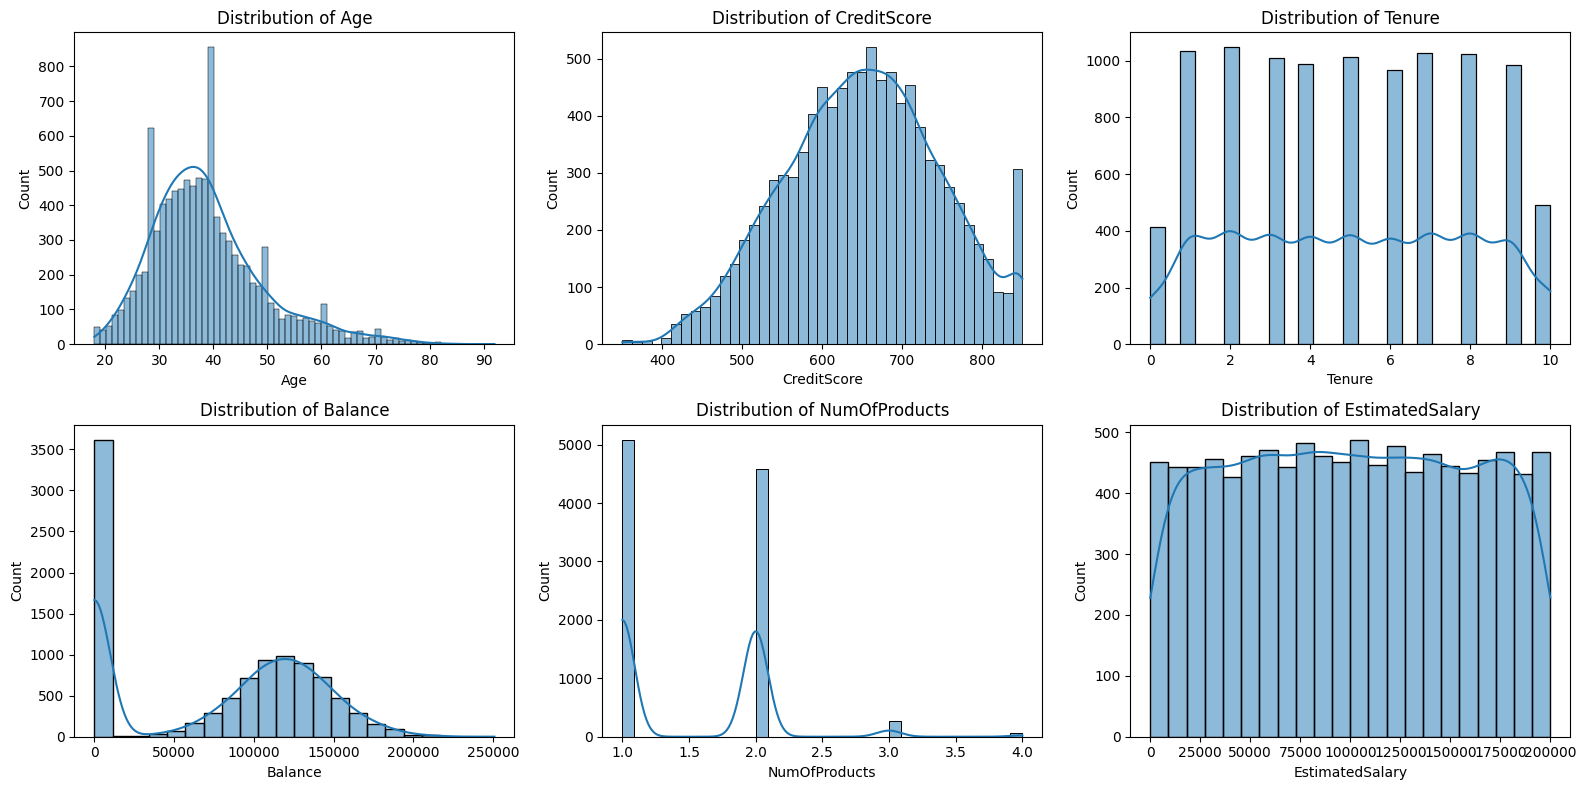

In [6]:
num_cols = ['Age', 'CreditScore', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flatten(), num_cols):
    sns.histplot(churn_df[col], kde=True, ax=ax)
    ax.set_title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

* `CreditScore` and `Age` are roughly bell-shaped (although age skews toward older customers).

* `Balance` has a large spike at zero then a fairly normal spread above it.

* `EstimatedSalary` is close to uniform. `Tenure` and `NumOfProducts` display a discrete distribution.

**Bi-variate analysis of continuous variables**

Customers who exited tend to be older, while credit score, estimated salary, and tenure show little difference between customers who stayed and those who exited.

/tmp/ipykernel_1794/413385954.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=churn_df, x='Exited', y=var, ax=ax, palette=['forestgreen','firebrick'])
/tmp/ipykernel_1794/413385954.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Stayed', 'Exited'])
/tmp/ipykernel_1794/413385954.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=churn_df, x='Exited', y=var, ax=ax, palette=['forestgreen','firebrick'])
/tmp/ipykernel_1794/413385954.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.se

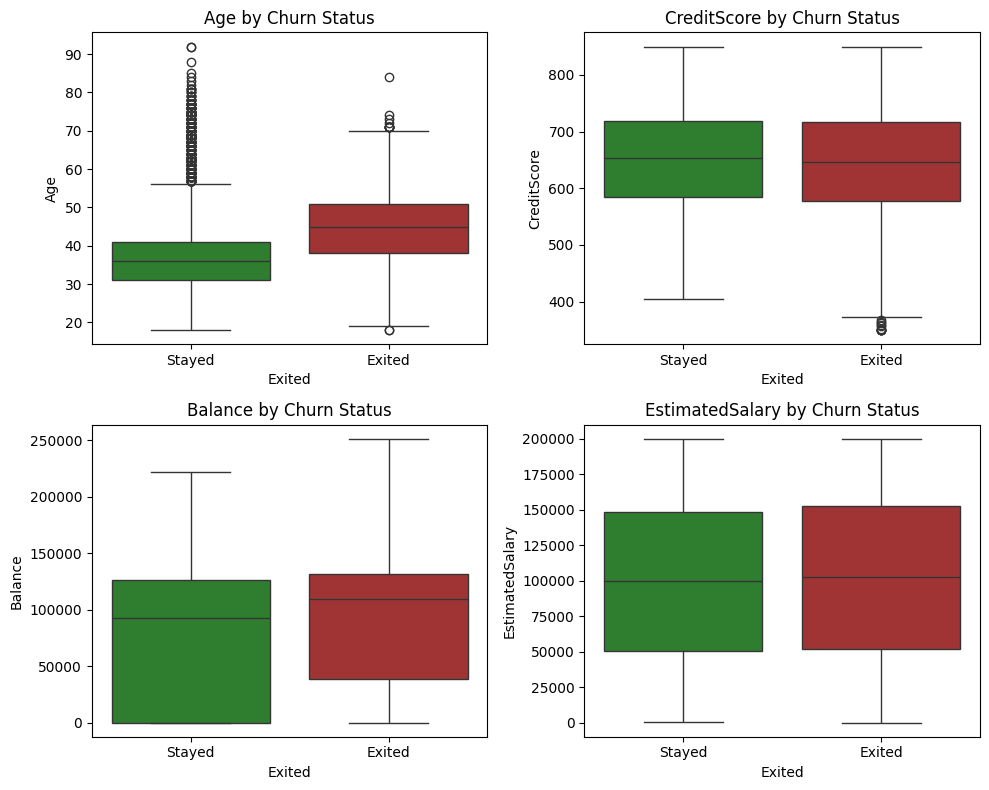

In [ ]:
num_cont = ['Age', 'CreditScore', 'Balance', 'EstimatedSalary']
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, var in zip(axes.flatten(), num_cont):
    sns.boxplot(data=churn_df, x='Exited', y=var, ax=ax, palette=['forestgreen','firebrick'])
    ax.set_title(f'{var} by Churn Status')
    ax.set_xticklabels(['Stayed', 'Exited'])
plt.tight_layout()
plt.show()

**Categorical/discrete variable distributions**

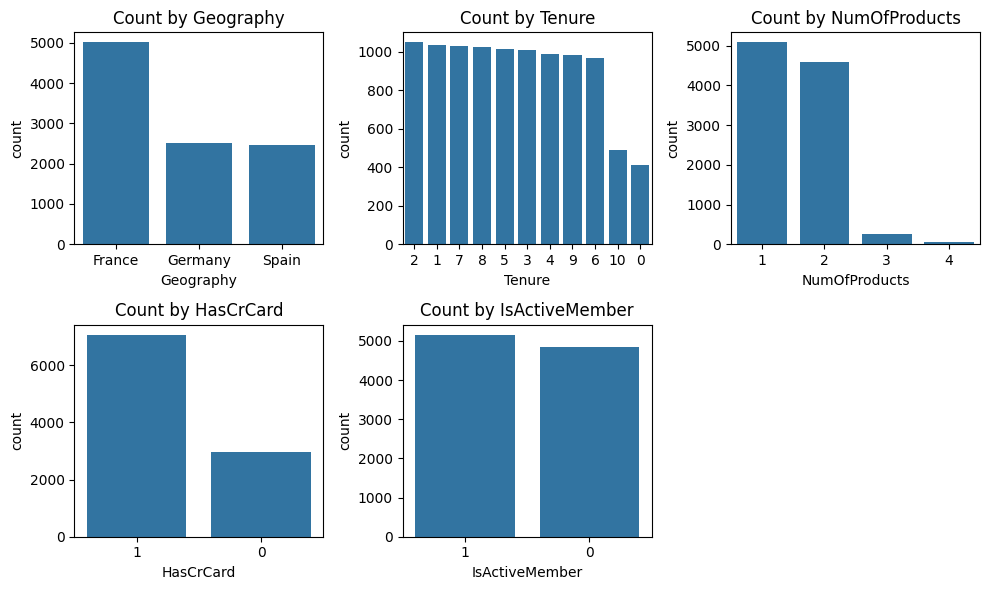

In [ ]:
cat_cols = ['Geography', 'Tenure', 'NumOfProducts', 'HasCrCard', 'IsActiveMember']
# Surname and Gender are excluded for an ethical analysis

fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for ax, col in zip(axes.flatten(), cat_cols):
    order = churn_df[col].value_counts().index
    sns.countplot(x=col, data=churn_df, order=order, ax=ax)
    ax.set_title(f'Count by {col}')
axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.show()

### **Churn Rate**

**Churn rate by numerical variables**

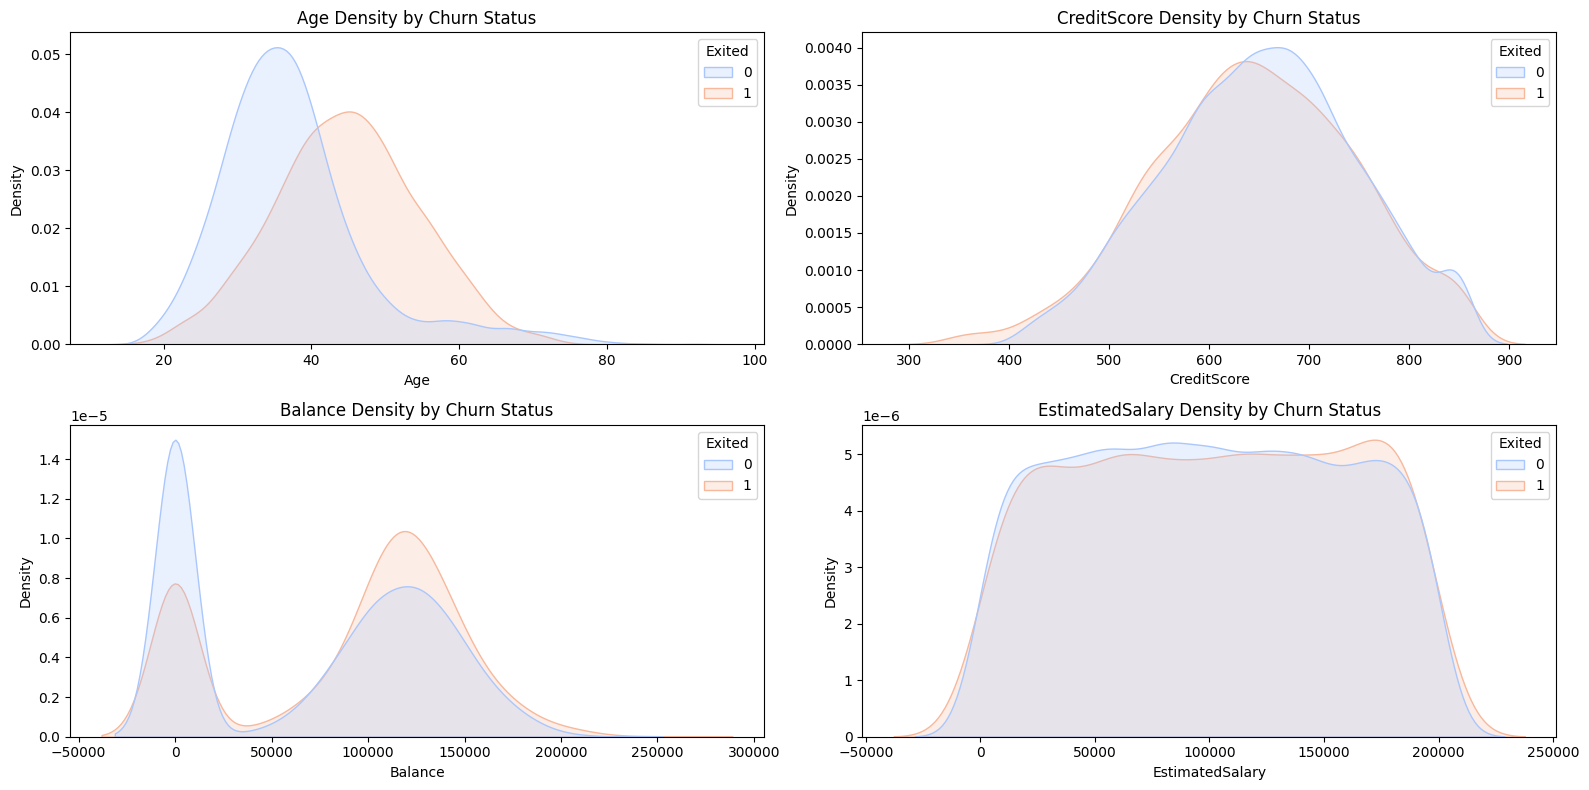

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for ax, col in zip(axes.flatten(), num_cont):
    sns.kdeplot(data=churn_df, x=col, hue='Exited', fill=True, common_norm=False,
                palette="coolwarm", ax=ax)
    ax.set_title(f'{col} Density by Churn Status')
plt.tight_layout()
plt.show()

> **Insights**
>
>* `Age` and `Balance` have some visible separation between churners and non-churners. Churners skew a bit older and are somewhat less concentrated at zero balance.

**Churn rate by category/discrete variables**

/tmp/ipykernel_1794/1240145044.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.index, y=rates.values, ax=ax, palette='flare')
/tmp/ipykernel_1794/1240145044.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.index, y=rates.values, ax=ax, palette='flare')
/tmp/ipykernel_1794/1240145044.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.index, y=rates.values, ax=ax, palette='flare')
/tmp/ipykernel_1794/1240145044.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in 

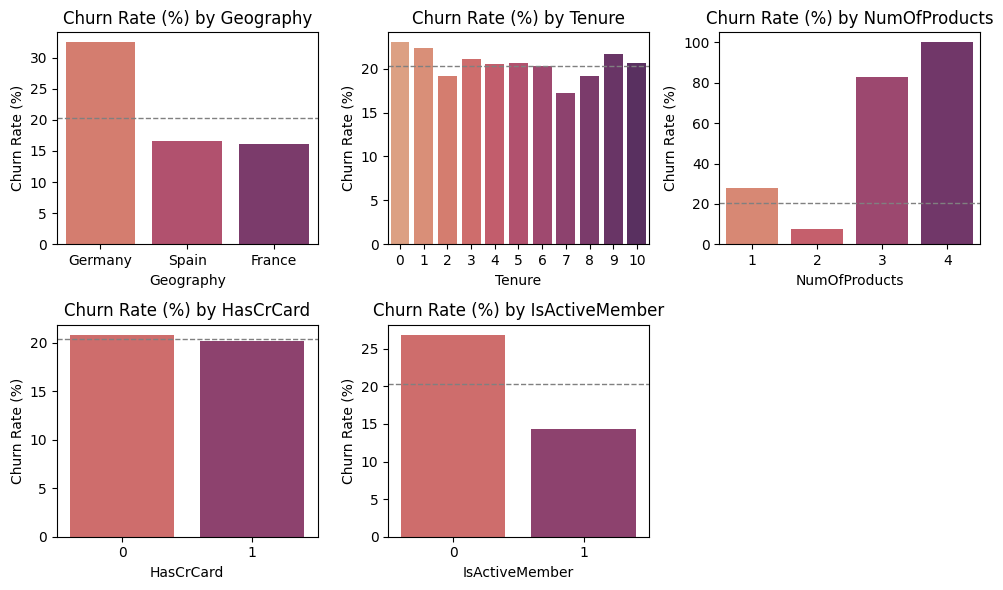

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for ax, col in zip(axes.flatten(), cat_cols):
    rates = churn_df.groupby(col, observed=True)['Exited'].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rates.index, y=rates.values, ax=ax, palette='flare')
    ax.set_title(f'Churn Rate (%) by {col}')
    ax.set_ylabel('Churn Rate (%)')
    ax.axhline(churn_df['Exited'].mean() * 100, color='gray', linestyle='--', linewidth=1)
axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.show()

>**Insights** (dashed line = overall churn rate, 20.37%):
>1. Customers from **Germany** have the highest churn rate. Germany has a churn rate of 32.4%, compared with around 16% for France and Spain.
>2. In terms of **number of products**, Customers with 2 products have the lowest churn rate, and shows a non-linear relationship (1 product is worse than 2, but 3-4 is worse still).
>3. **Inactive customers** are more likely to churn. Inactive customers have a churn rate of over 26%, compared with 14% for active customers.

**Further Exploration of No. of Products**

In [ ]:
product_summary = churn_df.groupby('NumOfProducts')['Exited'].agg(
    Total_Customers='count',
    Customers_Exited='sum',
    Churn_Rate='mean'
)

product_summary['Population_Ratio'] = (
    product_summary['Total_Customers'] / len(churn_df) * 100
).round(4)

product_summary['Churn_Rate'] = (
    product_summary['Churn_Rate'] * 100
).round(4)

product_summary

,Total_Customers,Customers_Exited,Churn_Rate,Population_Ratio
NumOfProducts,,,,
1,5084,1409,27.7144,50.84
2,4590,348,7.5817,45.90
3,266,220,82.7068,2.66
4,60,60,100.0000,0.60


> **Insights**
>1. Customers with 1-2 products make up 96.7% of the dataset, with those holding 2 products having the lowest churn rate at 7.6%, compared with 27.7% for those with 1 product.
>2. Churn is much higher among customers with 3–4 products at 82.7% and 100%, respectively, but these groups represent only 3.3% of customers.

### **Pair Plot**


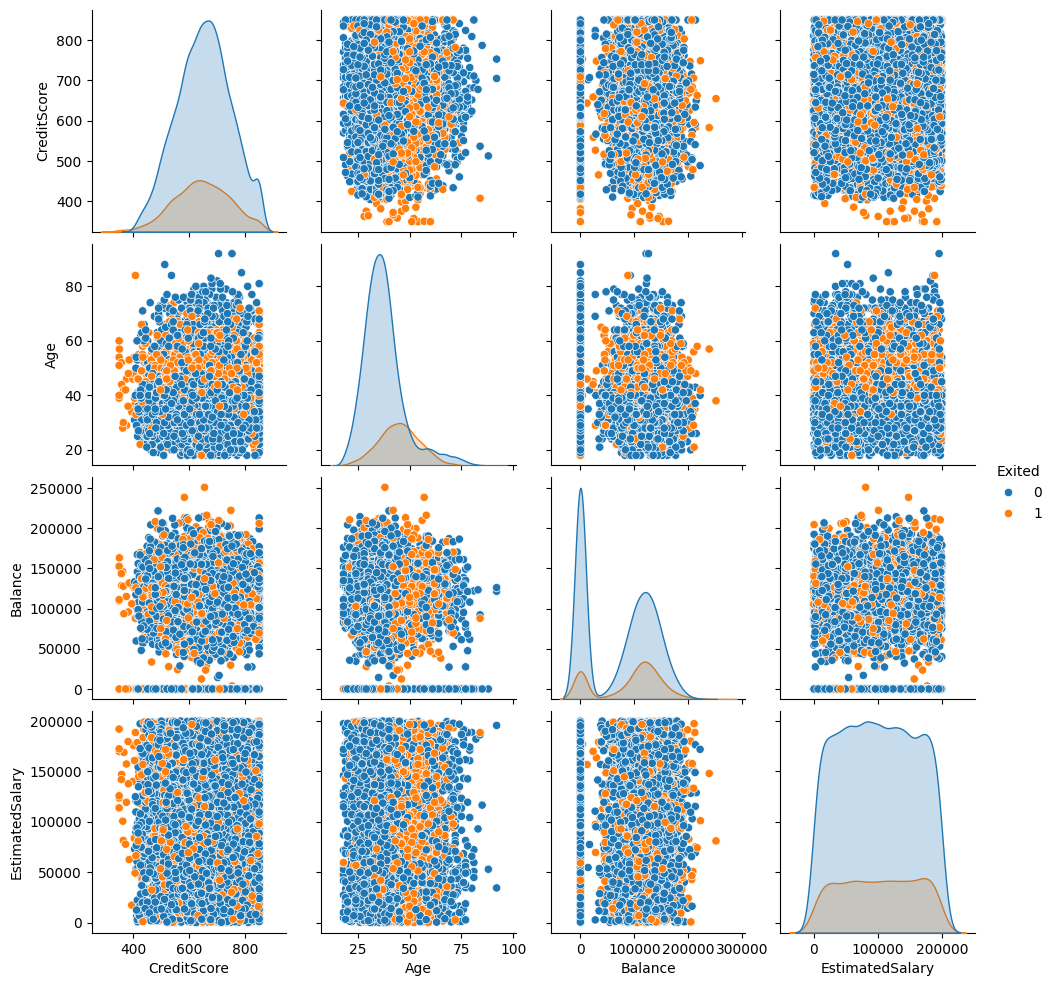

In [ ]:
sns.pairplot(churn_df[['CreditScore','Age','Balance','EstimatedSalary','Exited']], hue='Exited')


>**Insights**
>1. Customers who exited appear to be concentrated at older ages compared with customers who stayed. The orange distribution for `Age` is shifted to the right, suggesting that age may be an important predictor of churn.
>
>2. `CreditScore` and `EstimatedSalary` show substantial overlap between exited and non-exited customers. There is no obvious separation in the pairplot, suggesting their individual relationship with churn may be weaker.

### **Correlation**

We need to find a good idea of what feature to prioritize on our initial base model before we do any sort of optimization. Let's do some basic correlation tests


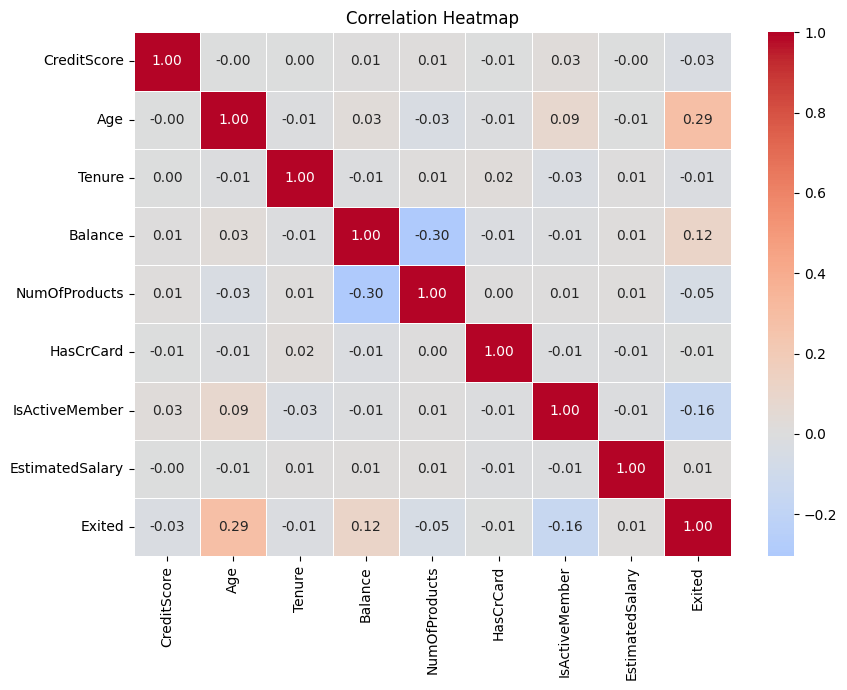

In [ ]:
num_for_corr = ['CreditScore','Age','Tenure','Balance','NumOfProducts',
                'HasCrCard','IsActiveMember','EstimatedSalary','Exited']
corr = churn_df[num_for_corr].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

>**Insights**
>1. Age - Strongest positive relationship
>2. IsActiveMember - Noticeable negative relationship
>3. Balance - Weak positive relationship

**Main Insights from the EDA**

1. `Age` appears to be one of the strongest predictors of churn. Older customers consistently show higher churn across the boxplot, pairplot, and correlation analysis.

2. Customer engagement matters. Inactive customers have substantially higher churn (26.9% vs. 14.3%), making `IsActiveMember` a potentially important predictor.

3. Number of products has a strong but nonlinear relationship with churn. Two-product customers have the lowest churn (7.6%), while churn rises sharply for 3–4 products. This relationship would be missed by relying only on correlation, and the small size of the 3–4 product groups should be considered during modeling.

4. `Geography` and `Balance` also differentiate churners. Customer from Germany and customers with higher balances show noticeably higher churn rates, suggesting these variables should be retained and categorical variables appropriately encoded.

5. Some variables show weak standalone relationships. `CreditScore`, `Tenure`, `EstimatedSalary`, and `HasCrCard` show little separation between churners and non-churners. However, they should not necessarily be dropped yet, because they may still contribute through interactions or nonlinear effects.

Strongest candidate predictors based on EDA in descending order are:

1. Age
2. NumOfProducts
3. IsActiveMember
4. Geography
5. Balance

## **Preprocessing**

**Design and assumptions**

* RowNumber, CustomerId, and Surname are identifiers with no predictive value, so they can be dropped
* Gender can be dropped for ethical consideration
* The dataset has zero missing values across all columns
* Geography is a low-cardinality categorical variable with 3 categories that requires one-hot encoding
* Numeric variables will not be changed and will be subjected to scaling later on when needed
* Age is the most skewed (skew ≈ 1.01)
* The target (Exited) is imbalanced (~80% stayed / 20% churned)


### **Dropping of variables**

In [ ]:
churn_backup = churn_df.copy()

In [7]:
churn_df = churn_df.drop(columns=['RowNumber', 'CustomerId', 'Surname', 'Gender'])
print(churn_df.shape)
churn_df.head()


(10000, 10)


,CreditScore,Geography,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,41,1,83807.86,1,0,1,112542.58,0
2,502,France,42,8,159660.80,3,1,0,113931.57,1
3,699,France,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,43,2,125510.82,1,1,1,79084.10,0


### **One-hot encoding**

In [8]:
geo_dummies = pd.get_dummies(churn_df['Geography'], prefix='Geography', drop_first=True)
churn_df = pd.concat([churn_df, geo_dummies], axis=1)

#   Geography_Germany  | Geography_Spain  | Actual country
#   -------------------|------------------|----------------
#           1          |        0         |    Germany
#           0          |        1         |    Spain
#           0          |        0         |    France (baseline)

churn_df = churn_df.drop(columns='Geography')
churn_df.columns.tolist()

for col in geo_dummies.columns:
    churn_df[col] = churn_df[col].astype(int)

print(churn_df.shape)
churn_df.head()

(10000, 11)


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain
0,619,42,2,0.00,1,1,1,101348.88,1,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1


### **Transformation**

     Transform   Skew
0   None (raw)  1.011
1        log1p  0.203
2  Yeo-Johnson -0.002


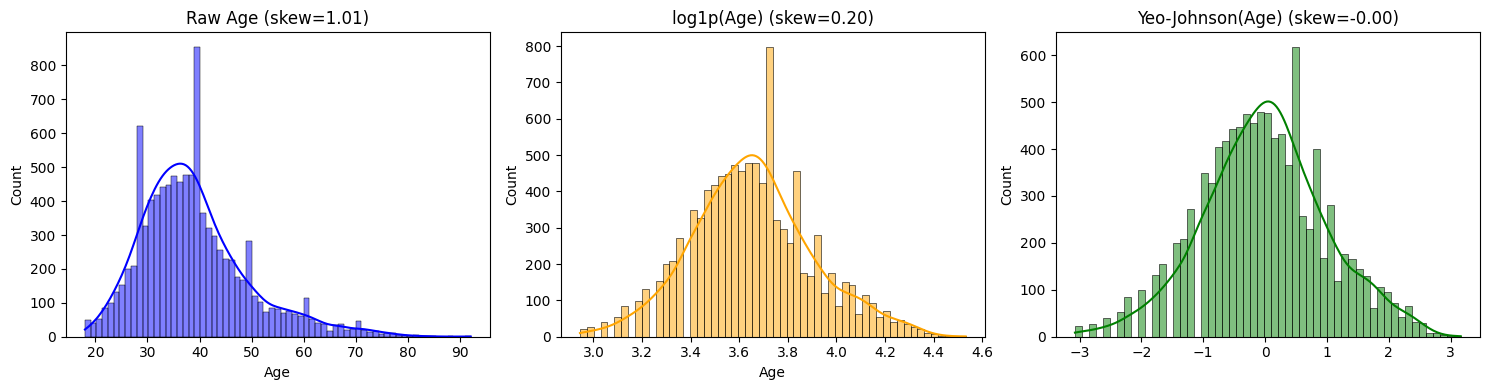

In [9]:
from sklearn.preprocessing import PowerTransformer

age_raw = churn_df['Age']
age_log = np.log1p(age_raw)
age_yeojohnson = PowerTransformer(method='yeo-johnson').fit_transform(
    age_raw.values.reshape(-1, 1)
).ravel()

skew_comparison = pd.DataFrame({
    'Transform': ['None (raw)', 'log1p', 'Yeo-Johnson'],
    'Skew': [age_raw.skew(), pd.Series(age_log).skew(), pd.Series(age_yeojohnson).skew()]
})
print(skew_comparison.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(age_raw, kde=True, ax=axes[0], color='blue')
axes[0].set_title(f"Raw Age (skew={age_raw.skew():.2f})")
sns.histplot(age_log, kde=True, ax=axes[1], color='orange')
axes[1].set_title(f"log1p(Age) (skew={pd.Series(age_log).skew():.2f})")
sns.histplot(age_yeojohnson, kde=True, ax=axes[2], color='green')
axes[2].set_title(f"Yeo-Johnson(Age) (skew={pd.Series(age_yeojohnson).skew():.2f})")
plt.tight_layout()
plt.show()

Since Age_yeojohnson skew is practically 0, we use this transformation instead of log skew.

# Train and Test Split

In [10]:
# Set seed
np.random.seed(280)

In [11]:
from sklearn.preprocessing import PowerTransformer
from sklearn.model_selection import train_test_split

X = churn_df.loc[:, churn_df.columns != 'Exited']
y = churn_df['Exited'].astype(float)

# stratify=y: target is ~80/20 imbalanced, so stratifying keeps that
# ratio consistent across train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y
)

# Fit the Age power transform on TRAIN first, then apply to both splits later, to avoid leakage
pt = PowerTransformer(method='yeo-johnson')
X_train = X_train.copy()
X_test = X_test.copy()
X_train['Age_yeojohnson'] = pt.fit_transform(X_train[['Age']])
X_test['Age_yeojohnson'] = pt.transform(X_test[['Age']])
X_train = X_train.drop(columns=['Age'])
X_test = X_test.drop(columns=['Age'])

columns = X_train.columns
print("Age skew (train, before transform... check via original):", churn_df['Age'].skew())
print("Age_yeojohnson skew (train):", X_train['Age_yeojohnson'].skew())
print(X_train.shape, X_test.shape)

Age skew (train, before transform... check via original): 1.0113202630234552
Age_yeojohnson skew (train): -0.0015473276059114651
(7000, 10) (3000, 10)


# Logistic Regression



In [12]:
# Base model using all variables
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

logreg = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=0)
logreg.fit(X_train_scaled, y_train)

y_logreg = logreg.predict(X_test_scaled)
y_prob_logreg = logreg.predict_proba(X_test_scaled)[:, 1]

print(f"Accuracy:  {accuracy_score(y_test, y_logreg):.6f}")
print(f"Precision: {precision_score(y_test, y_logreg):.6f}")
print(f"Recall:    {recall_score(y_test, y_logreg):.6f}")

Accuracy:  0.686000
Precision: 0.363110
Recall:    0.718494


# Random Forest

In [13]:
rf = RandomForestClassifier(
    n_estimators=300, max_depth=8, class_weight='balanced',
    random_state=0, n_jobs=-1
)
rf.fit(X_train, y_train)

y_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

print(f"Accuracy:  {accuracy_score(y_test, y_rf):.6f}")
print(f"Precision: {precision_score(y_test, y_rf):.6f}")
print(f"Recall:    {recall_score(y_test, y_rf):.6f}")

Accuracy:  0.822000
Precision: 0.551957
Recall:    0.669394


# Gradient Boost

In [14]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

gbm = GradientBoostingClassifier(
    n_estimators=300, max_depth=3, learning_rate=0.05, random_state=0
)
gbm.fit(X_train, y_train, sample_weight=sample_weights)

y_gbm = gbm.predict(X_test)
y_prob_gbm = gbm.predict_proba(X_test)[:, 1]

print(f"Accuracy:  {accuracy_score(y_test, y_gbm):.6f}")
print(f"Precision: {precision_score(y_test, y_gbm):.6f}")
print(f"Recall:    {recall_score(y_test, y_gbm):.6f}")

Accuracy:  0.805333
Precision: 0.515789
Recall:    0.721768


# SVM


In [15]:
# Scale the predictors

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, fbeta_score, make_scorer

# F2 weighs recall twice as heavily. For churn retention, a missed churner (false negative) costs the full customer relationship, while a false alarm just costs a wasted retention email/offer.
f2_scorer = make_scorer(fbeta_score, beta=2)

# Compare 3 kernels x 2 class-weight settings. n_iter per combo is sized for ~50 total CV fits (cv=2) so poly/rbf get reasonable coverage without the search taking too long.
kernels = ['linear', 'poly', 'rbf']
weight_settings = {'Not Balanced': None, 'Balanced': 'balanced'}
results = []

n_iter_settings = {
    ('linear', 'Not Balanced'): 4, ('linear', 'Balanced'): 4,
    ('poly', 'Not Balanced'): 4, ('poly', 'Balanced'): 4,
    ('rbf', 'Not Balanced'): 5, ('rbf', 'Balanced'): 4
}

param_grids = {
    'linear': {'svm__C': [0.01, 0.1, 1, 10, 100]},
    'poly': {'svm__C': [0.1, 1, 10], 'svm__degree': [2, 3, 4], 'svm__gamma': ['scale', 'auto', 0.1]},
    'rbf': {'svm__C': [0.1, 1, 10, 100], 'svm__gamma': ['scale', 'auto', 0.01, 0.1, 1]}
}

svm_fitted = {}  # keep every tuned estimator, keyed by (kernel, weight)

for kernel in kernels:
    for weight_name, weight_value in weight_settings.items():
        model = Pipeline([
            ('scaler', StandardScaler()),
            ('svm', SVC(kernel=kernel, class_weight=weight_value, random_state=0))
        ])
        n_iter = n_iter_settings[(kernel, weight_name)]
        random_search = RandomizedSearchCV(
            estimator=model, param_distributions=param_grids[kernel],
            n_iter=n_iter, scoring=f2_scorer, cv=2, n_jobs=-1, random_state=0
        )
        random_search.fit(X_train, y_train)
        best_model = random_search.best_estimator_
        svm_fitted[(kernel, weight_name)] = best_model

        y_pred = best_model.predict(X_test)
        best_params = random_search.best_params_

        results.append({
            'Kernel': kernel, 'Class Weight': weight_name,
            'Best C': best_params.get('svm__C', None),
            'Best Gamma': best_params.get('svm__gamma', None),
            'Best Degree': best_params.get('svm__degree', None),
            'CV F2 (1)': random_search.best_score_,
            'Accuracy': accuracy_score(y_test, y_pred),
            'Precision (0)': precision_score(y_test, y_pred, pos_label=0, zero_division=0),
            'Recall (0)': recall_score(y_test, y_pred, pos_label=0, zero_division=0),
            'F1 (0)': f1_score(y_test, y_pred, pos_label=0, zero_division=0),
            'Precision (1)': precision_score(y_test, y_pred, pos_label=1, zero_division=0),
            'Recall (1)': recall_score(y_test, y_pred, pos_label=1, zero_division=0),
            'F1 (1)': f1_score(y_test, y_pred, pos_label=1, zero_division=0),
            'F2 (1)': fbeta_score(y_test, y_pred, beta=2, pos_label=1, zero_division=0)
        })

svm_results_tuned = pd.DataFrame(results)
svm_results_tuned.round(3)

,Kernel,Class Weight,Best C,Best Gamma,Best Degree,CV F2 (1),Accuracy,Precision (0),Recall (0),F1 (0),Precision (1),Recall (1),F1 (1),F2 (1)
0,linear,Not Balanced,1.00,None,NaN,0.000,0.796,0.796,1.000,0.887,0.000,0.000,0.000,0.000
1,linear,Balanced,0.01,None,NaN,0.604,0.695,0.905,0.689,0.783,0.371,0.717,0.489,0.604
2,poly,Not Balanced,10.00,scale,4.0,0.479,0.853,0.870,0.959,0.912,0.730,0.439,0.548,0.477
3,poly,Balanced,1.00,0.1,3.0,0.647,0.796,0.919,0.817,0.865,0.500,0.717,0.589,0.660
4,rbf,Not Balanced,100.00,0.1,NaN,0.509,0.839,0.873,0.934,0.903,0.646,0.468,0.543,0.495
5,rbf,Balanced,1.00,0.1,NaN,0.659,0.792,0.919,0.810,0.861,0.492,0.720,0.585,0.659


# Naive Bayes

In [17]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV

nb_model = GaussianNB()
param_grid = {'var_smoothing': np.logspace(-11, -7, 9)}

grid_search_nb = GridSearchCV(
    estimator=nb_model, param_grid=param_grid, scoring=f2_scorer, cv=5, n_jobs=-1
)
grid_search_nb.fit(X_train_scaled, y_train)
best_nb = grid_search_nb.best_estimator_

y_pred_nb = best_nb.predict(X_test_scaled)

print(f"Best var_smoothing: {grid_search_nb.best_params_['var_smoothing']:.12e}")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_nb):.6f}")
print(f"Precision: {precision_score(y_test, y_pred_nb):.6f}")
print(f"Recall:    {recall_score(y_test, y_pred_nb):.6f}")
print(f"F1:        {f1_score(y_test, y_pred_nb):.6f}")
print(f"F2:        {fbeta_score(y_test, y_pred_nb, beta=2):.6f}")

Best var_smoothing: 1.000000000000e-11
Accuracy:  0.823000
Precision: 0.615607
Recall:    0.348609
F1:        0.445141
F2:        0.381720


# KNN

In [18]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

knn_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

knn_param_grid = {
    'knn__n_neighbors': [5, 9, 15, 21, 31, 45],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]    # Manhattan vs Euclidean
}

grid_search_knn = GridSearchCV(
    estimator=knn_pipe, param_grid=knn_param_grid, scoring=f2_scorer, cv=5, n_jobs=-1
)
grid_search_knn.fit(X_train, y_train)
best_knn = grid_search_knn.best_estimator_

y_pred_knn = best_knn.predict(X_test)

print(f"Best params: {grid_search_knn.best_params_}")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_knn):.6f}")
print(f"Precision: {precision_score(y_test, y_pred_knn):.6f}")
print(f"Recall:    {recall_score(y_test, y_pred_knn):.6f}")
print(f"F1:        {f1_score(y_test, y_pred_knn):.6f}")
print(f"F2:        {fbeta_score(y_test, y_pred_knn, beta=2):.6f}")

Best params: {'knn__n_neighbors': 5, 'knn__p': 2, 'knn__weights': 'distance'}
Accuracy:  0.832000
Precision: 0.649025
Recall:    0.381342
F1:        0.480412
F2:        0.415626


# Model Metrics

Let's look at some metrics to see how our classifier performed

In [19]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

# Initialize a list to store model results
model_comparison = []

# 1. Logistic Regression
# y_prob_logreg was computed using X_test_scaled
model_comparison.append({
    'Model': 'Logistic Regression',
    'Accuracy': accuracy_score(y_test, y_logreg),
    'Precision': precision_score(y_test, y_logreg, zero_division=0),
    'Recall': recall_score(y_test, y_logreg, zero_division=0),
    'F1-Score': f1_score(y_test, y_logreg, zero_division=0),
    'F2-Score': fbeta_score(y_test, y_logreg, beta=2, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_prob_logreg)
})

# 2. Random Forest
# y_prob_rf was computed using X_test
model_comparison.append({
    'Model': 'Random Forest',
    'Accuracy': accuracy_score(y_test, y_rf),
    'Precision': precision_score(y_test, y_rf, zero_division=0),
    'Recall': recall_score(y_test, y_rf, zero_division=0),
    'F1-Score': f1_score(y_test, y_rf, zero_division=0),
    'F2-Score': fbeta_score(y_test, y_rf, beta=2, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_prob_rf)
})

# 3. Gradient Boosting
# y_prob_gbm was computed using X_test
model_comparison.append({
    'Model': 'Gradient Boosting',
    'Accuracy': accuracy_score(y_test, y_gbm),
    'Precision': precision_score(y_test, y_gbm, zero_division=0),
    'Recall': recall_score(y_test, y_gbm, zero_division=0),
    'F1-Score': f1_score(y_test, y_gbm, zero_division=0),
    'F2-Score': fbeta_score(y_test, y_gbm, beta=2, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_prob_gbm)
})

# 4. SVM (RBF-Balanced)
# Access the best model from the randomized search for SVM
best_model_svm = svm_fitted[('rbf', 'Balanced')]
y_pred_svm = best_model_svm.predict(X_test)
y_score_svm = best_model_svm.decision_function(X_test)

svm_rbf_balanced_results = svm_results_tuned[
    (svm_results_tuned['Kernel'] == 'rbf') & (svm_results_tuned['Class Weight'] == 'Balanced')
].iloc[0]

model_comparison.append({
    'Model': 'SVM (RBF-Balanced)',
    'Accuracy': svm_rbf_balanced_results['Accuracy'],
    'Precision': svm_rbf_balanced_results['Precision (1)'],
    'Recall': svm_rbf_balanced_results['Recall (1)'],
    'F1-Score': svm_rbf_balanced_results['F1 (1)'],
    'F2-Score': svm_rbf_balanced_results['F2 (1)'],
    'ROC-AUC': roc_auc_score(y_test, y_score_svm)
})

# 5. Naive Bayes
# y_pred_nb and best_nb are available from previous execution
y_prob_nb = best_nb.predict_proba(X_test_scaled)[:, 1]
model_comparison.append({
    'Model': 'Naive Bayes',
    'Accuracy': accuracy_score(y_test, y_pred_nb),
    'Precision': precision_score(y_test, y_pred_nb),
    'Recall': recall_score(y_test, y_pred_nb),
    'F1-Score': f1_score(y_test, y_pred_nb),
    'F2-Score': fbeta_score(y_test, y_pred_nb, beta=2),
    'ROC-AUC': roc_auc_score(y_test, y_prob_nb)
})

# 6. KNN
# y_pred_knn and best_knn are available from previous execution
y_prob_knn = best_knn.predict_proba(X_test)[:, 1]
model_comparison.append({
    'Model': 'KNN',
    'Accuracy': accuracy_score(y_test, y_pred_knn),
    'Precision': precision_score(y_test, y_pred_knn, zero_division=0),
    'Recall': recall_score(y_test, y_pred_knn, zero_division=0),
    'F1-Score': f1_score(y_test, y_pred_knn, zero_division=0),
    'F2-Score': fbeta_score(y_test, y_pred_knn, beta=2, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_prob_knn)
})


metrics_df = pd.DataFrame(model_comparison)
metrics_df.round(6)

,Model,Accuracy,Precision,Recall,F1-Score,F2-Score,ROC-AUC
0,Logistic Regression,0.686000,0.363110,0.718494,0.482418,0.600876,0.765379
1,Random Forest,0.822000,0.551957,0.669394,0.605030,0.642072,0.854105
2,Gradient Boosting,0.805333,0.515789,0.721768,0.601637,0.668384,0.857473
3,SVM (RBF-Balanced),0.791667,0.492170,0.720131,0.584718,0.659077,0.842708
4,Naive Bayes,0.823000,0.615607,0.348609,0.445141,0.381720,0.787969
5,KNN,0.832000,0.649025,0.381342,0.480412,0.415626,0.766216


**Note: F2-Score is our primary metric for model selection.** F1 weighs precision and recall equally, but for churn retention the two mistakes aren\'t equally costly - missing an actual churner (false negative) loses the customer entirely, while flagging someone who wasn\'t going to leave (false positive) only costs a wasted retention email or offer. Since under-catching churners is the more expensive error, we weight recall more heavily than precision using F2 (recall counted 2x). Precision, Recall, and F1 are still reported alongside it for context.

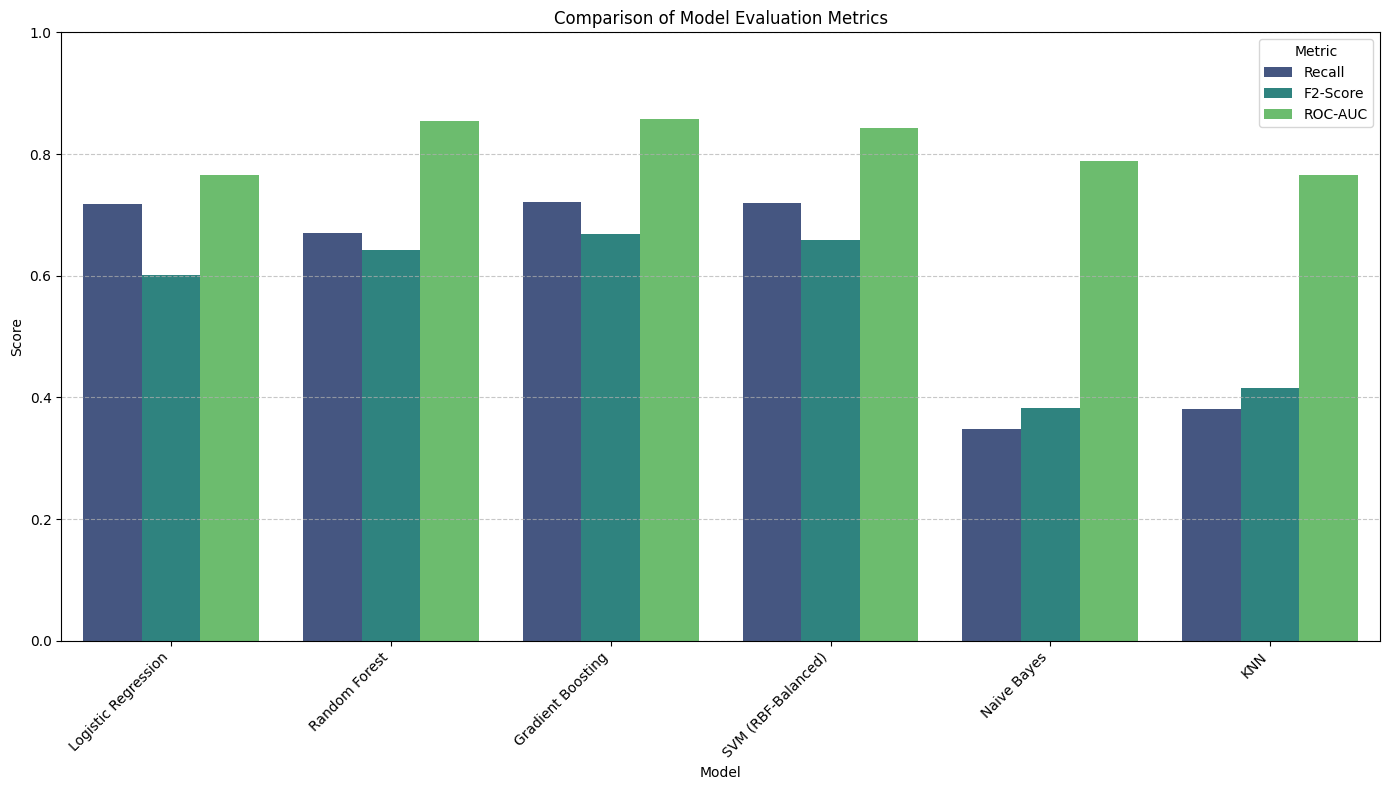

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select the metrics to visualize
metrics_to_plot = ['Recall', 'F2-Score', 'ROC-AUC']

# Melt the DataFrame to a long format for easier plotting with seaborn
metrics_melted = metrics_df.melt(
    id_vars=['Model'],
    value_vars=metrics_to_plot,
    var_name='Metric',
    value_name='Score'
)

# Create the grouped bar chart
plt.figure(figsize=(14, 8))
sns.barplot(
    data=metrics_melted,
    x='Model',
    y='Score',
    hue='Metric',
    palette='viridis'
)

plt.title('Comparison of Model Evaluation Metrics')
plt.xlabel('Model')
plt.ylabel('Score')
plt.xticks(rotation=45, ha='right') # Rotate model names for readability
plt.ylim(0, 1) # Metrics are typically between 0 and 1
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Model Selection Criteria: Highest Recall and F2-score

* Among the untuned models compared above, Random Forest and Gradient Boosting have the highest Recall and F2-score.

* Checking their confusion matrices, Gradient Boosting correctly identifies more churners and has fewer false negatives.

* **For this reason, Gradient Boosting is our strongest untuned candidate**

Confusion Matrix

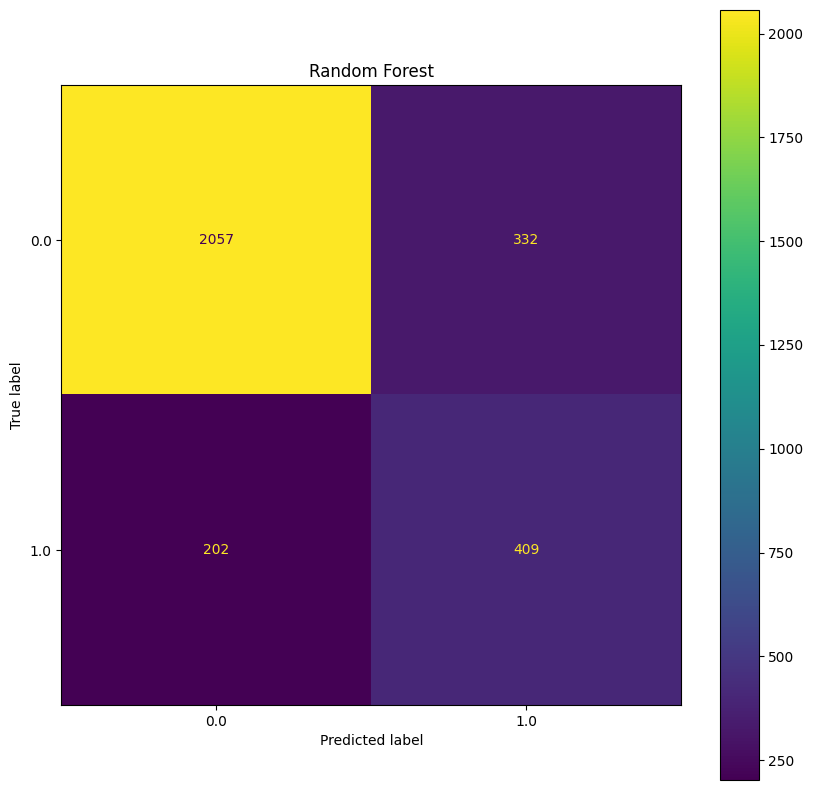

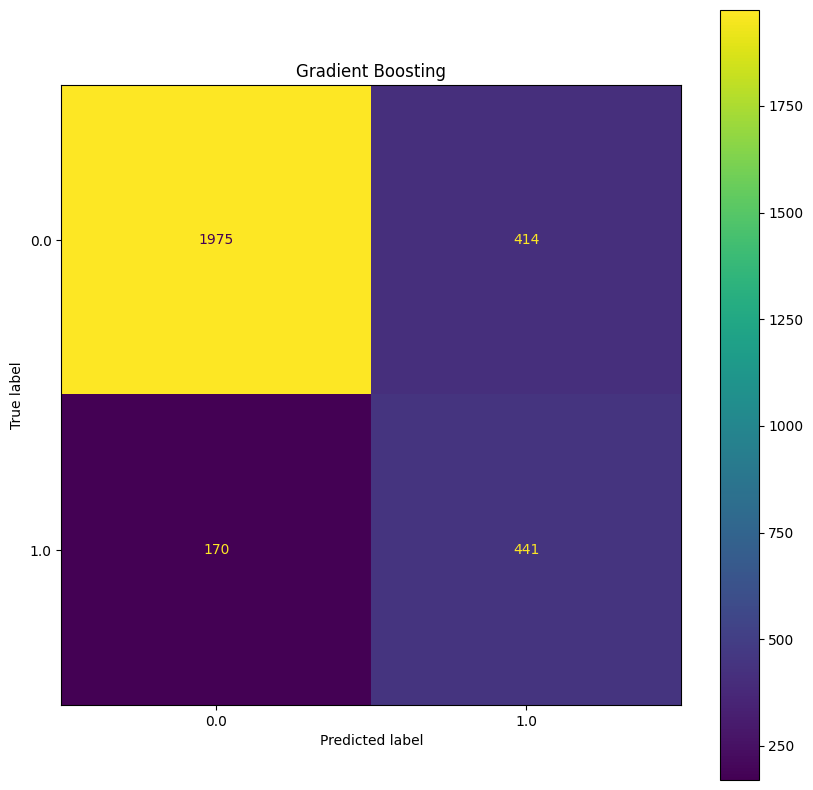

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay.from_estimator(rf, X_test, y_test, ax=ax)
ax.set_title("Random Forest")
plt.show()

fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay.from_estimator(gbm, X_test, y_test, ax=ax)
ax.set_title("Gradient Boosting")
plt.show()

An ROC curve (receiver operating characteristic curve) is a graph showing the performance of a classification model at all classification thresholds.

AUC stands for "Area under the ROC Curve." That is, AUC measures the entire two-dimensional area underneath the entire ROC curve (think integral calculus) from (0,0) to (1,1).

![ROC AUC](https://glassboxmedicine.files.wordpress.com/2019/02/roc-curve-v2.png?w=576 "ROC AUC")


ROC is a probability curve and AUC represents the degree or measure of separability. It tells how much the model is capable of distinguishing between classes. Higher the AUC, the better the model is at predicting 0s as 0s and 1s as 1s.


![TPR FPR](https://miro.medium.com/max/500/1*7_2ai1_ICde2nq83ksvZIg.png "TPR FPR")

To generate the ROC Curve we compute the TPR and FPR for using our model and a random classifier (no skill) and plot the resulting values

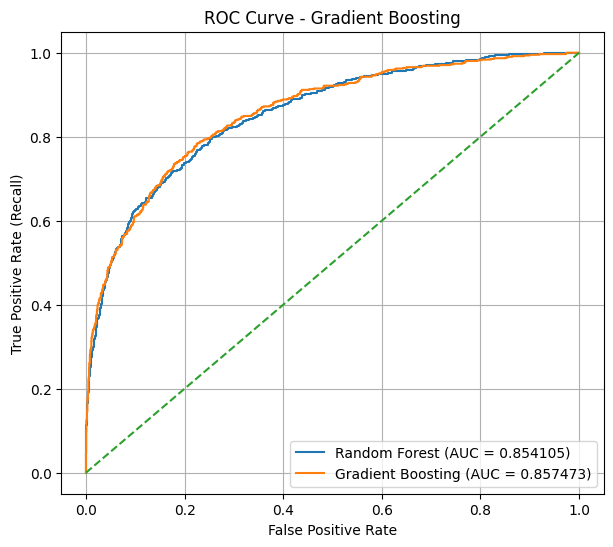

In [22]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get predicted probabilities for class 1 (churn)
y_prob_gbm = gbm.predict_proba(X_test)[:, 1]

# Calculate ROC curve
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_gbm, tpr_gbm, _ = roc_curve(y_test, y_prob_gbm)

# Calculate AUC
auc_rf = roc_auc_score(y_test, y_prob_rf)
auc_gbm = roc_auc_score(y_test, y_prob_gbm)

# Plot ROC curve
plt.figure(figsize=(7, 6))
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.6f})')
plt.plot(fpr_gbm, tpr_gbm, label=f'Gradient Boosting (AUC = {auc_gbm:.6f})')

# Random classifier reference line
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve - Gradient Boosting')
plt.legend()
plt.grid()

plt.show()

# Hyperparameter Tuning of Gradient Boosting Model

In [23]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score, roc_auc_score
)

sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

gbm = GradientBoostingClassifier(random_state=0)

param_grid = {
    'n_estimators': [100, 200, 300, 400, 600],
    'learning_rate': [0.005, 0.01, 0.03, 0.05, 0.1],
    'max_depth': [2, 3, 4, 5],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5],
    'subsample': [0.7, 0.8, 0.9, 1.0]
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

gbm_search = RandomizedSearchCV(
    estimator=gbm, param_distributions=param_grid,
    n_iter=40, scoring=f2_scorer, cv=cv, random_state=0, n_jobs=-1, verbose=1
)
gbm_search.fit(X_train, y_train, sample_weight=sample_weights)

print("Best Parameters:")
print(gbm_search.best_params_)
print("\nBest CV F2 Score:")
print(gbm_search.best_score_)

best_gbm = gbm_search.best_estimator_
y_gbm = best_gbm.predict(X_test)
y_prob_gbm = best_gbm.predict_proba(X_test)[:, 1]

print("\nTest Set Performance")
print(f"Accuracy:  {accuracy_score(y_test, y_gbm):.6f}")
print(f"Precision: {precision_score(y_test, y_gbm):.6f}")
print(f"Recall:    {recall_score(y_test, y_gbm):.6f}")
print(f"F1 Score:  {f1_score(y_test, y_gbm):.6f}")
print(f"F2 Score:  {fbeta_score(y_test, y_gbm, beta=2):.6f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_gbm):.6f}")

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best Parameters:
{'subsample': 1.0, 'n_estimators': 400, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 3, 'learning_rate': 0.03}

Best CV F2 Score:
0.6753610597453071

Test Set Performance
Accuracy:  0.802667
Precision: 0.510932
Recall:    0.726678
F1 Score:  0.600000
F2 Score:  0.670088
ROC-AUC:   0.857945


In [24]:
gbm_tuned_metrics = {
    'Accuracy':  accuracy_score(y_test, y_gbm),
    'Precision': precision_score(y_test, y_gbm),
    'Recall':    recall_score(y_test, y_gbm),
    'F1-Score':  f1_score(y_test, y_gbm),
    'F2-Score':  fbeta_score(y_test, y_gbm, beta=2),
    'ROC-AUC':   roc_auc_score(y_test, y_prob_gbm)
}

gbm_baseline_metrics = metrics_df.loc[metrics_df['Model'] == 'Gradient Boosting'].iloc[0]

metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'F2-Score', 'ROC-AUC']
gbm_comparison = pd.DataFrame({
    'Metric': metric_names,
    'Baseline GBM': [gbm_baseline_metrics[m] for m in metric_names],
    'Tuned GBM': [gbm_tuned_metrics[m] for m in metric_names]
})
gbm_comparison.round(3)

,Metric,Baseline GBM,Tuned GBM
0,Accuracy,0.805,0.803
1,Precision,0.516,0.511
2,Recall,0.722,0.727
3,F1-Score,0.602,0.600
4,F2-Score,0.668,0.670
5,ROC-AUC,0.857,0.858


# Feature Importance

Using the tuned Gradient Boosting model, the most important predictors were determined.

`Age`, `NumOfProducts`, and `Balance` turned out to be the most important features

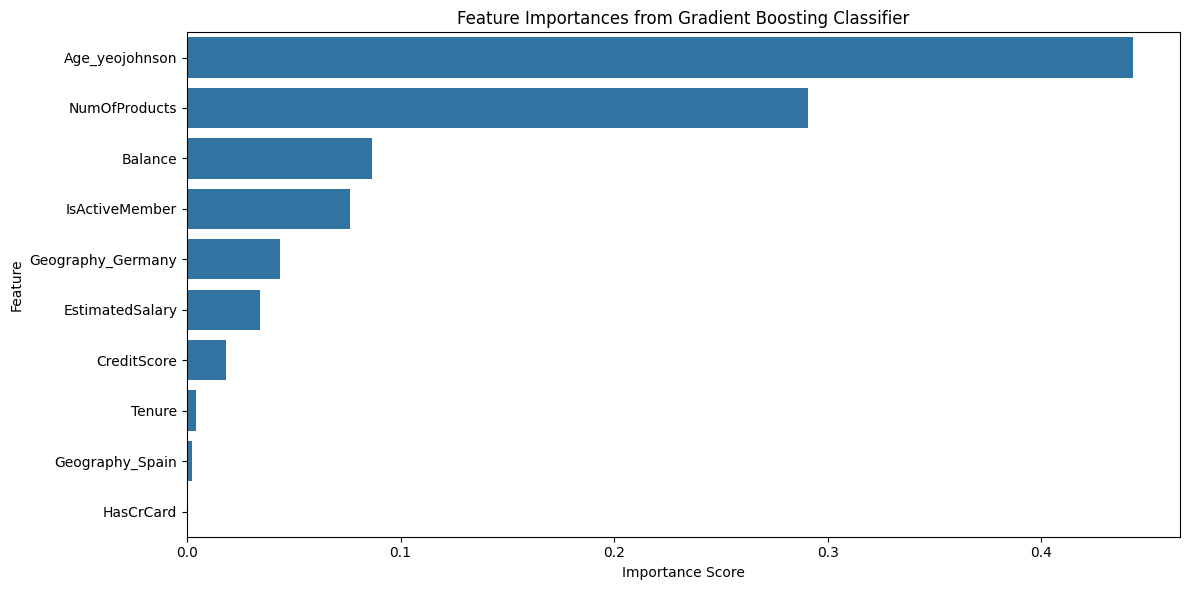

In [25]:
from sklearn.ensemble import GradientBoostingClassifier

# Get feature importance scores
importances = best_gbm.feature_importances_

# Create a DataFrame for better visualization
feature_importances_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importances
})

# Sort the features by importance in descending order
feature_importances_df = feature_importances_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importances_df)
plt.title('Feature Importances from Gradient Boosting Classifier')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# SHAP

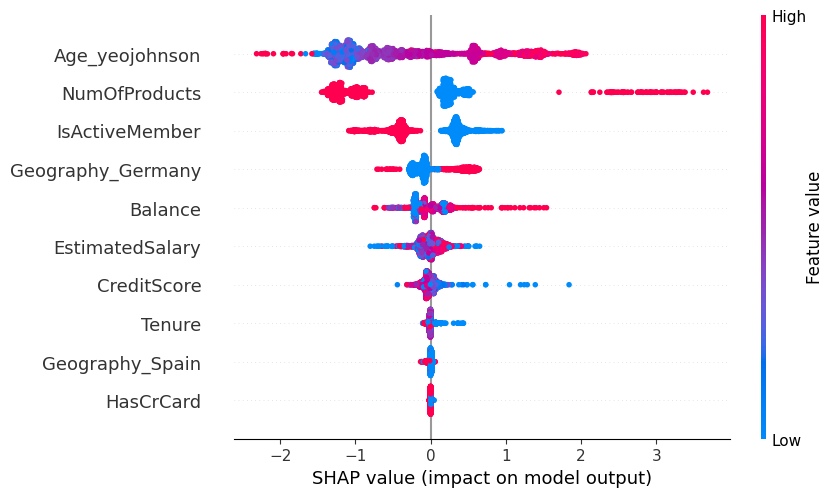

In [26]:
import shap
import matplotlib.pyplot as plt

explainer = shap.TreeExplainer(best_gbm)
shap_values = explainer(X_test)

shap.plots.beeswarm(shap_values, max_display=15)

* **Age is the strongest driver of churn prediction**. Higher values (red points) are concentrated on the positive SHAP side, meaning older customers tend to push the model toward predicting churn. Younger customers generally push the prediction toward staying.

* **Number of products has a strong relationship with churn**. Some high product-count observations have very large positive SHAP values, while other high values have negative SHAP values. This is consistent with EDA where 2 products had relatively low churn, while 3–4 products had much higher churn.

* **Inactive members are at risk for churning**. `IsActiveMember`, red points (1 = active) are mainly on the negative side, whereas blue points (0 = inactive) are mostly on the positive side.

* **Customers in Germany tend to have higher predicted churn**. For Geography_Germany, observations where the feature is present tend to fall on the positive SHAP side. This agrees with EDA showing higher churn among German customers.

* **Higher balances generally increase predicted churn risk**. Higher Balance values are more visible on the positive SHAP side, while lower balances tend to have neutral or negative effects. This suggests the model considers high-balance customers an important retention group.

Everything else, `CreditScore`, `Tenure`, `EstimatedSalary`, `Geography_Spain`, and `HasCrCard`, cluster close to zero. They're in the model, but they're not doing the heavy lifting, so they are not in the priority for interventions.

# Interventions

1. **Product-fit intervention** — `NumOfProducts`
Customers with high predicted churn and problematic product combinations receive a product review. The bank can simplify unnecessary products, review fees, or recommend more suitable alternatives.

2. **Engagement intervention**— `IsActiveMember`
High-risk inactive customers receive targeted re-engagement through personalized communication, customer-service check-ins, and relevant loyalty or engagement offers.

3. **High-value retention** — `Balance`
Customers with both a high balance and high churn probability are prioritized for relationship-manager outreach, account reviews, and service recovery.

4. **Market-specific retention**

Age, Geography, CreditScore, and Tenure will be used as diagnostic/context features to tailor the type of support

>**Note:** German customers average nearly double the balance of customers elsewhere (€119,730 vs. €62,002), suggesting Germany's elevated churn rate is driven in large part by its high concentration of high-balance customers, the same segment flagged as high-risk by the Balance-based intervention above (rather than being a purely geographic effect).

In [ ]:
churn_df.groupby('Geography_Germany')['Balance'].mean()

,Balance
Geography_Germany,
0,62001.873114
1,119730.116134


Other possible interventions related to `Age`

* **Tailored Communication and Products**: Older customers might have different needs and preferences. Personalized offers, financial products, or communication styles that resonate with their life stage could be effective.

* **Financial Planning and Advisory Services**: Offering free or discounted financial planning services could be highly valuable. This addresses potential concerns about retirement, estate planning, or managing assets, which might be more prevalent among older age groups.

* **Digital Literacy Support**: If churn is related to difficulty using
online banking platforms, providing workshops, tutorials, or dedicated customer support for digital tools could help them stay engaged.

* **Customer Loyalty Programs**: Special loyalty programs or benefits designed to reward long-term customers, particularly those in older age brackets, can enhance their sense of value and belonging.

* **Proactive Outreach**: Instead of waiting for signs of dissatisfaction, proactively reaching out to older customers to check on their banking experience and offer assistance could build stronger relationships. Example: online deposit of PDC